In [27]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [37]:
conn = duckdb.connect("../storage/database/leagues/England.ddb", read_only=True)
table_name = "39-2010-xg"
df = conn.execute(f"""
    SELECT
        round,
        AVG(x_league_avg_goals) AS x_league_avg_goals,
        AVG(y_league_avg_goals) AS y_league_avg_goals
    FROM "{table_name}"
    GROUP BY round
    ORDER BY round
""").df()
# Close the database connection
conn.close()
# Extract the round number after the hyphen
df["round"] = df["round"].str.extract(r"-\s*(\d+)").astype(int)

# Sort rounds numerically
df = df.sort_values("round").reset_index(drop=True)
df

,round,x_league_avg_goals,y_league_avg_goals
0,1,0.000000,0.000000
1,2,1.800000,0.800000
2,3,2.050000,1.150000
3,4,1.833333,1.033333
4,5,1.750000,1.125000
5,6,1.740000,1.120000
6,7,1.633333,1.150000
7,8,1.571429,1.100000
8,9,1.550000,1.112500
9,10,1.522222,1.111111


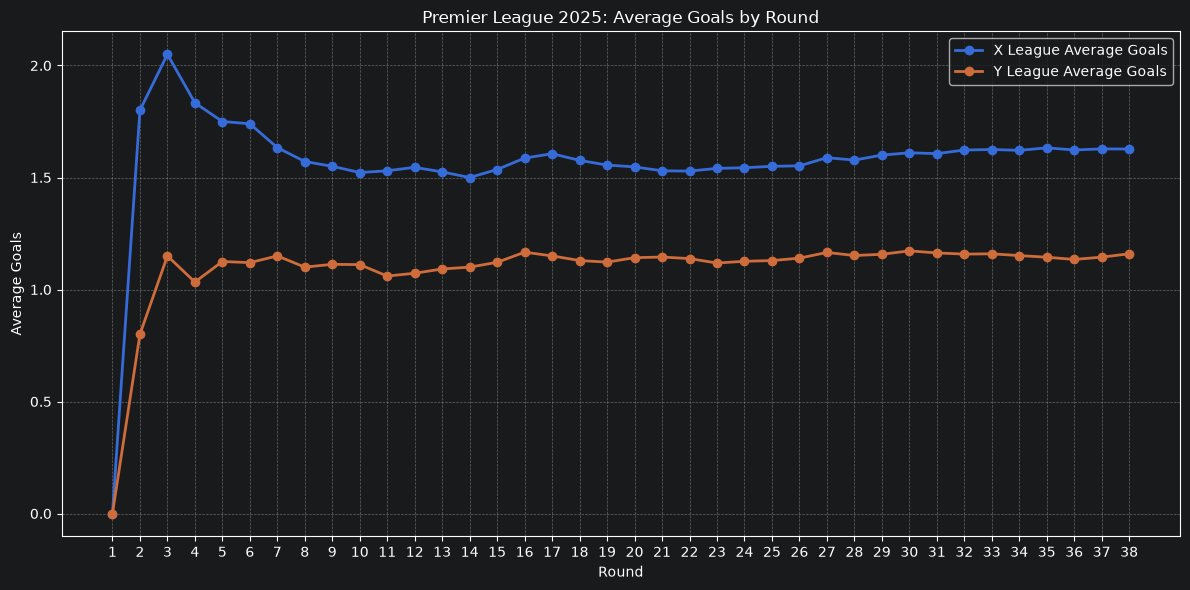

In [38]:
# Plot both curves
plt.figure(figsize=(12, 6))

plt.plot(
    df["round"],
    df["x_league_avg_goals"],
    marker="o",
    linewidth=2,
    label="X League Average Goals"
)

plt.plot(
    df["round"],
    df["y_league_avg_goals"],
    marker="o",
    linewidth=2,
    label="Y League Average Goals"
)

# Chart formatting
plt.title("Premier League 2025: Average Goals by Round")
plt.xlabel("Round")
plt.ylabel("Average Goals")
plt.xticks(df["round"])
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()